# Projet Leyenda - Livrable 1

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:
![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Dans ce ***premier livrable***, nous créeons un CNN via la bibliothéque tensorFlow, pour cela nous utilisons un dataset que nous importons et effectuant un pré traitement, en créeant des dossiers dans le dossier mère : *process* True et False, permettant de regroupé les groupes d'images pour ensuite les splité en différents sets : Train et Test. 

Détail du ***Livrable 1:***
- Le code TensorFlow ainsi qu'un schéma de l'architecture du réseau de neurones. Toutes les parties doivent être détaillée dans le notebook : les paramètre du réseau, la fonction de perte ainsi que l'algorithme d'optimisation utilisé pour l’entraînement.
- Un graphique contenant l'évolution de l'erreur d’entraînement ainsi que de l'erreur de test et l'évolution de l'accuracy pour ces deux sets.
- L'analyse de ces résultats, notamment le compromis entre biais et variance (ou sur-apprentissage et sous-apprentissage).
- Une description des méthodes potentiellement utilisables pour améliorer les compromis biais/variance : technique de régularisation, drop out, early-stopping, ...

***Pour le CNN , nous créeons l'architecture suivante:***
- Importation du dataset et la division en 75%/15%/10%
- La normalisation des données /255 pour que les valeurs soit comprise entre 0.0 et 1.0
- Nous initialiation le modèle avec plusieurs couches de Convulation (conv2d) et pooling (Maxpooling2D)
- Nous transformons ensuite l'image en un vecteur de une dimension avec Flatten
- Pour finir avec les dense Layers et une sortie binaire avec la formule mathématique utilisé ici sigmoid


# Etape 1:
### Schéma de notre architecture :
![Image demandé](src/Architecture_CNN.png)

Voici le schéma de notre architecture, qui sera utilisée pour la suite de notre livrable. Il est composé de plusieurs parties :

* **L'input**
* **La normalisation**
* **Les couches de convolution**
* **Les couches de pooling**
* **La couche de neurones (Dense)**
* **La fonction d'activation sigmoïde**

La normalisation est effectuée dès le début pour ramener les valeurs RGB des pixels (initialement de 0 à 255) sur une échelle de 0 à 1. 

Nous sommes partis sur deux couches de convolution pour les images de moins de 128 pixels, et sur trois couches pour les images de 128 pixels. L'idée est d'augmenter le nombre de filtres à chaque couche afin de capter de plus en plus de détails au fur et à mesure. Un Dropout est placé juste après la deuxième couche de pooling (ainsi qu'après la troisième pour le format 128). Cela permet d'éviter l'overfitting en désactivant aléatoirement une partie des neurones pendant l'entraînement.

Chaque couche de convolution est accompagnée d'une couche de MaxPooling afin de réduire la dimension spatiale de l'image et de préparer l'étape du Flatten. Ensuite, nous arrivons justement au Flatten. Comme dit précédemment, le MaxPooling a permis de réduire les dimensions (H pour la hauteur et W pour la largeur). C'est essentiel car le Flatten va aplatir les données en un vecteur à une seule dimension pour permettre à la couche Dense d'opérer. Puisque le nombre de paramètres à l'entrée de la couche Dense dépend de ce volume (H × W × N, où N est le nombre de filtres), diminuer H et W permet de réduire considérablement le nombre de paramètres de la couche Dense. 

Pour finir, la couche Dense fait son travail pour sortir le résultat de la classification et utilise la fonction d'activation sigmoïde afin de ramener ce résultat final entre 0 et 1.
### Importation des librairies

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import plotly.express as px
from DL_dataset import *

### Les paramètres et hyperparametres utilisé:
- Epoch : est le nombre de fois que le modèle s'entraine
- $\lambda$ : est la valeur d'une pénalité appliqué sur l2 régularization, cette pénalité s'applique sur les poids trop grand.
- learning rate : est la taille des pas effectués par un modèle lors de sa mise à jour pour minimiser l'erreur, plus le pas est petit plus le modèle prendra du temps à s'entrainer mais évite l'overfitting.
- BATCH_SIZE : est une valeur qui désigne le nombre d'exemples d'entraînement traités lors d'une même et unique itération, les valeurs les plus courantes sont 8,16 et 32.
- Dropout : Désactive certains neurones pour éviter l'overfitting, il faut souvent tester plusieurs valeurs comprise entre 0 et 1 pour obtenir le meilleur parametres mais le plus souvent on trouve une valeur entre 0.1 et 0.4.
- Patience : Est le nombre d'epoch maximun passé si sur par exemple la valeur désigné, ici la valeur loss ne s'améliore pas après le nombre d'epoch défini par la patience est atteinte, alors le modèle va s'arreter.
- Train et Test split: sont le % de chaque pour la réparatition des images. Souvent on trouve 80/20 ou 75/25, le Train sera utilisé pour l'entrainement du modèle et le Test pour la validation du modèle.
- img_size: Résolution de l'image

In [2]:
Epoch=10
lambda_l2=0.001
learning_rate=0.01
BATCH_SIZE=32
Dropout=0.1
Patience=5
train_split=0.75
test_split=0.25
img_size=64

### Téléchargement et préprocessing des données
Chaque step peut etre activé ou non, la première est le téléchargement des fichiers zip, la deuxieme étape est de dézipé les fichiers et la dernière est de fusionner les datasets dans le dossier processing avec un sous dossier True pour les photo et les autres Dataset dans False.

In [8]:
step_DL=True      
step_unzip=True
step_process=True

urls=[
    "https://drive.google.com/file/d/1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX/view?usp=sharing",
    "https://drive.google.com/file/d/1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy/view?usp=sharing",
    "https://drive.google.com/file/d/1J-WupkQTuwmniUiO-E0rMQzsl2Pi1J5o/view?usp=sharing",
    "https://drive.google.com/file/d/1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_/view?usp=sharing",
    "https://drive.google.com/file/d/16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T/view?usp=sharing"
]

folder_raw = Path(f"./data/raw")
folder_process = Path(f"./data/processing")

if not os.path.exists(folder_raw):
    os.makedirs(folder_raw)

if not os.path.exists(folder_process):
    os.makedirs(folder_process)

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

if step_process==True:
    file_list=copy(folder_process)
    Check_corruption(folder_process)

File download:


Downloading...
From (original): https://drive.google.com/uc?id=1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX
From (redirected): https://drive.google.com/uc?id=1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX&confirm=t&uuid=282b8b9b-85d6-4bc9-993a-b425459b21e3
To: c:\Users\hmjhl\Documents\GitHub\Cnn\data\raw\downloaded_file1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX.zip
100%|██████████| 4.61G/4.61G [02:17<00:00, 33.5MB/s]


Donwload complete


Downloading...
From (original): https://drive.google.com/uc?id=1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy
From (redirected): https://drive.google.com/uc?id=1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy&confirm=t&uuid=59024793-44e4-4122-a5f5-7f7e159de174
To: c:\Users\hmjhl\Documents\GitHub\Cnn\data\raw\downloaded_file1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy.zip
100%|██████████| 1.62G/1.62G [09:54<00:00, 2.73MB/s]


Donwload complete


...

Donwload complete


Downloading...
From (original): https://drive.google.com/uc?id=1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_
From (redirected): https://drive.google.com/uc?id=1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_&confirm=t&uuid=858344cf-2725-4aea-8231-0eea322d6151
To: c:\Users\hmjhl\Documents\GitHub\Cnn\data\raw\downloaded_file1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_.zip
100%|██████████| 47.5M/47.5M [00:01<00:00, 29.3MB/s]


Donwload complete


Downloading...
From (original): https://drive.google.com/uc?id=16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T
From (redirected): https://drive.google.com/uc?id=16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T&confirm=t&uuid=335b39b2-4834-493f-9978-0921bdf017b6
To: c:\Users\hmjhl\Documents\GitHub\Cnn\data\raw\downloaded_file16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T.zip
100%|██████████| 663M/663M [00:59<00:00, 11.1MB/s] 


Donwload complete
File extract for data\raw\downloaded_file16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T.zip
File extract for data\raw\downloaded_file1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX.zip
File extract for data\raw\downloaded_file1J-WupkQTuwmniUiO-E0rMQzsl2Pi1J5o.zip
File extract for data\raw\downloaded_file1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_.zip
File extract for data\raw\downloaded_file1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy.zip
Painting to data\processing\False
Photo to data\processing\True
Schematics to data\processing\False
Sketch to data\processing\False
Text to data\processing\False
Corrupted image detected and deleted: data\processing\False\Painting_painting_02662.jpg
Corrupted image detected and deleted: data\processing\False\Schematics_desktop.ini


### Division des datasets en un dataset Train et False

In [9]:
dossier_racine = Path(f"./data/processing/")
train_set = tf.keras.preprocessing.image_dataset_from_directory(
  dossier_racine,
  validation_split= 1-train_split,
  subset =  "training",
  seed=42,
  batch_size=BATCH_SIZE,
  image_size=(img_size,img_size)
)

test_set = tf.keras.preprocessing.image_dataset_from_directory(
  dossier_racine,
  validation_split= test_split,
  subset =  "validation",
  seed=42,
  batch_size=BATCH_SIZE,
  image_size=(img_size,img_size),
)

AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Found 41398 files belonging to 2 classes.
Using 31049 files for training.
Found 41398 files belonging to 2 classes.
Using 10349 files for validation.


### Création de l'architecture du modèle

In [8]:
model_layers = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    #Normalisation
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
]

if img_size == 256: 
    model_layers.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.1),
    ])

model_layers.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model = keras.Sequential(model_layers)

### Choix de la métrique et de l'optimizer
On utilise un optimiser pour mettre à jour les poids en utilisant la descente de gradient lors de la backpropagation, le plus souvent on utilise l'agorithme Adam qui mets à jour automatiquement le Learning rate pour chaque poids en améliorant la vitesse et les performances d'entrainement. Lorsqu'on compile le modèle avec TensorFlow, on choisit la métrique que l'on peut observé, ici l'accuracy de notre modèle. La loss fonction est utilisé pour calculé la différence entre les prédictions de notre modèle et les véritables images. Plusieurs méthodes sont disponible pour le CNN:

- Binary Cross-Entropy (Pour la classification binaire)
- Categorical Cross-Entropy (Pour la classification de plusieurs classes)
- Sparse Categorical Crossentropy (Pour la classification de plusieurs classes, mais les labels sont des numéros entier 1,2 etc...)

On va donc utiliser ici la ***Binary Cross-Entropy***.

In [14]:
model.compile(optimizer ="adam",  #A COMPLETER
              loss =  "binary_crossentropy",
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,281 (6.20 MB)

 Trainable params: 1,625,281 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

### Lancement du modèle
Avec la fonction ***Model.fit*** va permettre de lancer l'entrainement avec différents paramètres tels que le nombre d'epochs, est le nombre de fois que le modèle s'entraine, ***validation_data*** est quant à lui, la partie avec lequel la data sera testé, ici le dataset défini plus haut *test_set*.

In [15]:
history = model.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.8286 - loss: 0.3406 - val_accuracy: 0.8700 - val_loss: 0.2812
Epoch 2/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.8785 - loss: 0.2645 - val_accuracy: 0.8968 - val_loss: 0.2413
Epoch 3/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9032 - loss: 0.2221 - val_accuracy: 0.9034 - val_loss: 0.2245
Epoch 4/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9236 - loss: 0.1799 - val_accuracy: 0.9100 - val_loss: 0.2150
Epoch 5/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9435 - loss: 0.1393 - val_accuracy: 0.9091 - val_loss: 0.2342
Epoch 6/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9602 - loss: 0.1015 - val_accuracy: 0.9108 - val_loss: 0.2568
Epoch 7/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9725 - loss: 0.0712 - val_accuracy: 0.9097 - val_loss: 0.2943
Epoch 8/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9831 - loss: 0.0468 - 

# Etape 2:
### Graphique des résultats obtenu pour le modèle:
Dans ce graphique, nous regardons l'accuracy et la fonction de perte dans ce graphique au cours de l'entrainement à chaque epoch.

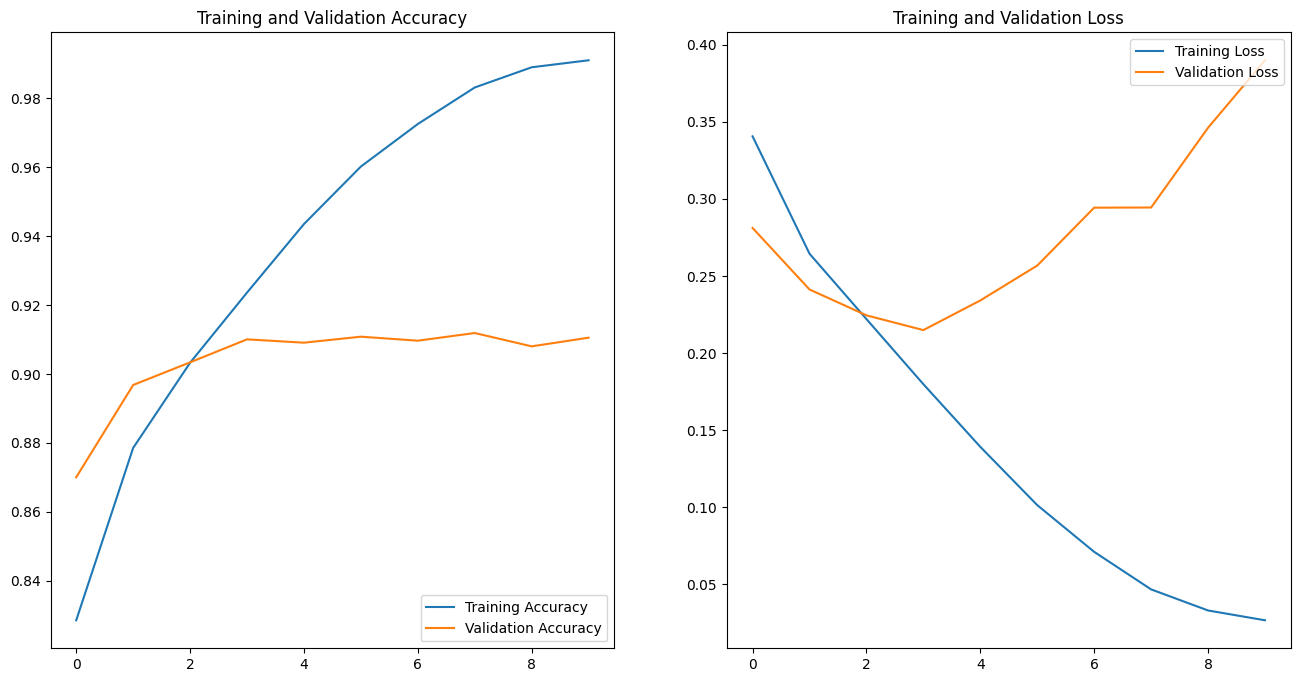

In [16]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(Epoch)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

***Résultat:*** En observant les deux graphs obtenus, on remarque une grosse différence dans la fonction de perte entre celui de Train et celui de validation, ce qui indique une grande variance donc un overfitting, pour résoudre ce problème, nous utiliserons différents paramètres à notre disposition pour pouvoir régler cet overfitting tout en évitant l'under-fitting.

# Etape 3:
### Modèle avec les différentes méthodes contre l'overfitting

En premier lieu, nous essayons avec le dropout.

In [ ]:
model_layers = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    # Normalisation
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(Dropout), 
]

if img_size == 256: 
    model_layers.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
    ])

model_layers.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(Dropout), 
    layers.Dense(1, activation='sigmoid')
])

model_dropout = keras.Sequential(model_layers)

model_dropout.compile(optimizer="adam", 
              loss="binary_crossentropy",
              metrics=['accuracy'])

In [11]:
history_dropout = model_dropout.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10


C:\Users\hmjhl\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


971/971 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - accuracy: 0.8191 - loss: 0.3451 - val_accuracy: 0.8611 - val_loss: 0.2854
Epoch 2/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8657 - loss: 0.2825 - val_accuracy: 0.8807 - val_loss: 0.2579
Epoch 3/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.8890 - loss: 0.2469 - val_accuracy: 0.8779 - val_loss: 0.2667
Epoch 4/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9038 - loss: 0.2201 - val_accuracy: 0.9089 - val_loss: 0.2181
Epoch 5/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9199 - loss: 0.1876 - val_accuracy: 0.8996 - val_loss: 0.2309
Epoch 6/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9319 - loss: 0.1615 - val_accuracy: 0.9064 - val_loss: 0.2217
Epoch 7/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9458 - loss: 0.1337 - val_accuracy: 0.8995 - val_loss: 0.2593
Epoch 8/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9559 - loss: 0.1118 - val_accurac

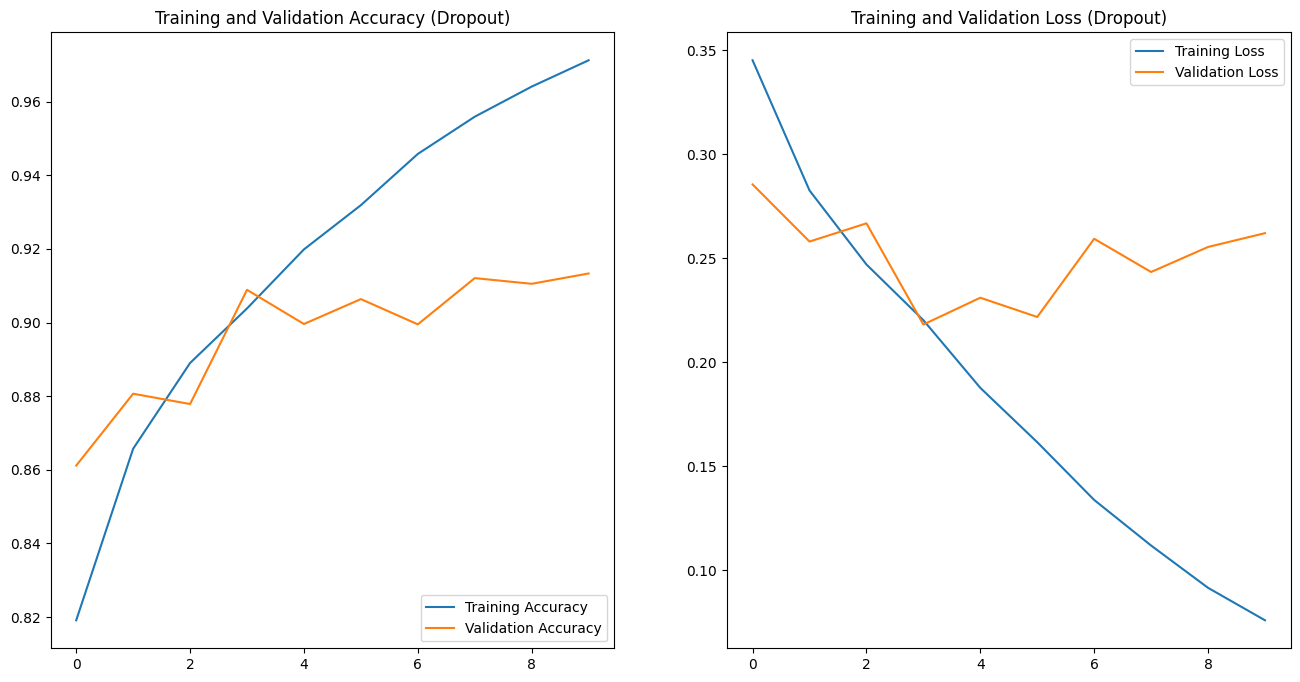

In [12]:
acc = history_dropout.history['accuracy']
val_acc = history_dropout.history['val_accuracy']

loss = history_dropout.history['loss']
val_loss = history_dropout.history['val_loss']

epochs_range = range(Epoch)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy (Dropout)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss (Dropout)')
plt.show()

En comparant ce résultat avec le modèle sans dropout, nous pouvons voir une amélioration sur la fonction loss, même si le résultat ne reste pas bon. Pour ce qui est de l'accuracy, on voit une très légère amélioration, mais l'overfitting reste présent à partir de la 3ème époque. 

Nous allons essayer une autre solution de régularisation : l'augmentation des données. Le but de cette technique est d'augmenter le nombre de données afin de combler certains déséquilibres de classes ou simplement de donner plus de cas d'usage au modèle pour le perfectionner. Cette augmentation de données se fait en inclinant, en zoomant ou en changeant l'axe de symétrie de l'image. Cela permet de changer la place des pixels afin d'éviter que ce soient exactement les mêmes images, et donc d'empêcher la mémorisation.

Pour ce prochain modèle, nous allons utiliser la data augmentation de TensorFlow.

In [13]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

model_layers_final = [
    keras.Input(shape=(None, None, 3)), 
    
    layers.Resizing(img_size, img_size),
    
    data_augmentation, 
    
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
]

if img_size == 256: 
    model_layers_final.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
    ])

model_layers_final.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_final = keras.Sequential(model_layers_final)

model_final.compile(optimizer="adam", 
              loss="binary_crossentropy",
              metrics=['accuracy'])

In [14]:
history_final = model_final.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.8255 - loss: 0.3393 - val_accuracy: 0.8375 - val_loss: 0.3294
Epoch 2/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.8651 - loss: 0.2854 - val_accuracy: 0.8425 - val_loss: 0.3178
Epoch 3/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.8767 - loss: 0.2668 - val_accuracy: 0.8639 - val_loss: 0.2898
Epoch 4/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.8888 - loss: 0.2489 - val_accuracy: 0.8545 - val_loss: 0.3666
Epoch 5/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.8969 - loss: 0.2335 - val_accuracy: 0.8856 - val_loss: 0.2528
Epoch 6/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.9030 - loss: 0.2256 - val_accuracy: 0.8871 - val_loss: 0.2646
Epoch 7/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9060 - loss: 0.2160 - val_accuracy: 0.9040 - val_loss: 0.2241
Epoch 8/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.9106 - loss: 0.2075 - 

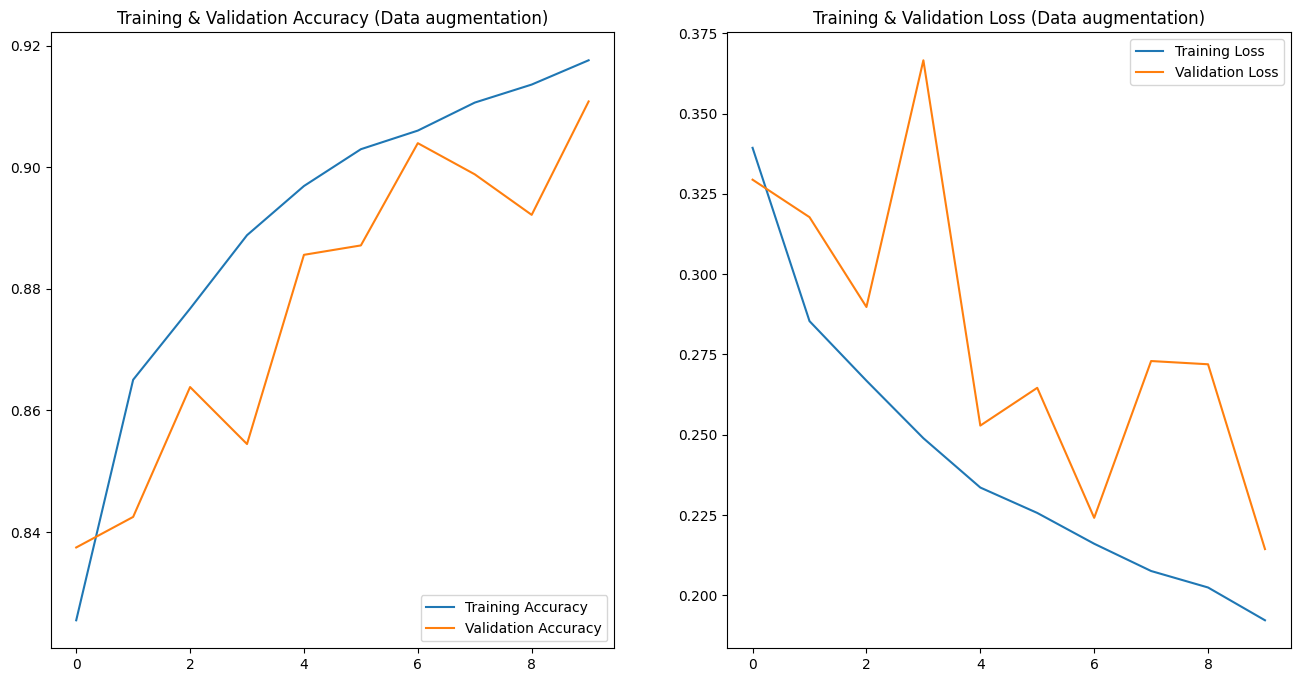

In [15]:
acc_final = history_final.history['accuracy']
val_acc_final = history_final.history['val_accuracy']

loss_final = history_final.history['loss']
val_loss_final = history_final.history['val_loss']

epochs_range = range(Epoch)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_final, label='Training Accuracy')
plt.plot(epochs_range, val_acc_final, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy (Data augmentation)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_final, label='Training Loss')
plt.plot(epochs_range, val_loss_final, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss (Data augmentation)')
plt.show()

On voit que le résultat est ici plus intéressant, cependant on y retrouve quand même un overfitting. Pour cela, nous allons ajouter différentes méthodes comme le early stopping, l2_regularization...

In [ ]:
#code à rajouter; choisir la meilleure version

Nous avons essayé plusieurs possibilités sur le modèle avec la class weight, la data augmentation sur le train set sur True et False, et une autre data augmentation pour équilibrer la différence entre les photo dites True et le reste, car de base nous avions une différence d'environ 15k images. #a completer

### Comparaison entre les différents modèles avec différents paramètres:

In [ ]:
folder_model = Path(f"./Model")
folder_comparaison = Path(f"./data/comparaison_set")

model_name=[]

#chargement de tout les modèles sauvegardé avec les différents test éffectués
for path in folder_model.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".keras", ".h5", ".hdf5"
    }:
        model_name.append(path)

result=[]
for i, model_x in enumerate(model_name, start=1):
    print(f"Évaluation : {model_x.name}")

    #Detection de la taille pour la résolution
    match model_x.name:
        case name if "128x128" in name:
            img_size = (128, 128)
        case name if "64x64" in name:
            img_size = (64, 64)
        case name if "32x32" in name:
            img_size = (32, 32)

    Validation_set = tf.keras.utils.image_dataset_from_directory(
        folder_comparaison,
        image_size=img_size,
        batch_size=BATCH_SIZE,
        label_mode="binary"  
    )

    model_y = tf.keras.models.load_model(model_x)
    loss, accuracy = model_y.evaluate(Validation_set,verbose=0) 

    result.append({
        "model_id": f"M{i}",
        "model": model_x.name,
        "loss": loss,
        "accuracy": accuracy
    }) 

df = pd.DataFrame(result)

fig_acc = px.bar(
    df, 
    x="model_id", 
    y="accuracy", 
    color="accuracy",
    color_continuous_scale="Teal",
    hover_data=["model", "accuracy"],
    title="Accuracy for each Model"
)
fig_acc.update_layout(xaxis_title="Model ID", yaxis_title="Accuracy")
fig_acc.show()

# Graphique interactif pour la Loss avec Plotly
fig_loss = px.bar(
    df, 
    x="model_id", 
    y="loss", 
    color="loss",
    color_continuous_scale="Teal",
    hover_data=["model", "loss"],
    title="Loss for each Model"
)
fig_loss.update_layout(xaxis_title="Model ID", yaxis_title="Loss")
fig_loss.show()

Évaluation : Modele_cnn_128x128_Patience_5_Dropout_0.1_lambda_l2_0.001.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_12_Dropout_0.1_lambda_l2_0.001.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_12_Dropout_0.1_lambda_l2_0.005.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_12_Dropout_0.1_lambda_l2_0.01.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_12_Dropout_0.2_lambda_l2_0.001.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_12_Dropout_0.2_lambda_l2_0.005.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_12_Dropout_0.2_lambda_l2_0.01.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_5_Dropout_0.1_lambda_l2_0.001.keras
Found 48 files belonging to 2 classes.
Évaluation : Modele_cnn_32x32_Patience_5_Dropout_0.1_lambda_l2_0.005.keras
Found 4

Le meilleur modèle obtenu est...

# Etape 4
Pour faire face à l'under-fitting et d'over-fitting, nous avons utilisé plusieurs principes très connu et disponible sur tensorflow comme ***Dropout***, qui va nous servir pour contrer l'over-fitting en désactivent certains neurones, nous avons testés plusieurs valeurs comme 0.1, 0.2 et 0.4. Les deux meilleurs résultats ont été avec 0.1 et 0.2. Comme autre méthodes, nous avons rajouté dans les dense layer, ***un l2_regularization*** Va appliqué une pénalité sur les poids trop grand, cela force pendant l'optimisation des poids se rapproche de 0, la valeur pour définir la puissance de cette pénalité est choisit via l'hyperparamètres **lambda ($\lambda$**) la puissance de cette pénalité. La dernière technique est le ***Early stopping Callback***, on l'utilise pour stopper l'entrainement du modèle quand la valeur cible ne s'améliore pas, on défini un hyperparamètre patience qui s'y active après x fois défini est atteinte et que pendant cette période il y a eu aucune amélioration et limité l'overfitting car le modèle est devenu "paraisseux".
Pour l'under-fitting, nous jouons avec les différents hyperparametres et faisons aussi la data augmentation qui permet d'avoir dans le train set un nombre similaire de True et False, pour que son entrainement soit claire et détaillé.